# PyTorch pairwise ranker

## Goal

Compare a neural ranker with the frozen LightGBM reference using the
same historical candidates, periods and full-reference ranking metrics.

Initial fitting uses six training cutoffs, from 2020-07-22 to 2020-08-26.
Validation covers [2020-09-02, 2020-09-09).

A candidate label of zero means no purchase observed in the target
window, not proven dislike.

Preprocessing and identifier vocabularies are fitted on training only.
Final confirmation remains reserved.

## Execution and evidence

Restart the kernel and run this notebook in order to create a new experiment
campaign. The UUID-based run directory preserves previously completed campaigns.
Save the notebook before running fitting and export cells.

The recorded outputs were produced before unchanged model definitions were
extracted into `atelier_ai.neural_ranker`. This organization change has not
been followed by a fresh training replay.

Final confirmation is in `09_final_confirmation.ipynb`. That notebook loads
an explicitly selected frozen campaign and does not require this kernel.


In [4]:
from pathlib import Path
import json

import duckdb
import numpy as np
import pandas as pd
import torch

from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

import atelier_ai
from atelier_ai.feature_export import file_sha256
from atelier_ai.ranking_data import prepare_ranker_inputs
from atelier_ai.recommendation_features import (
    FEATURE_COLUMNS,
    EXPECTED_MISSING_FEATURES,
)
from atelier_ai.temporal_protocol import load_protocol

PROJECT_ROOT = Path(atelier_ai.__file__).resolve().parents[2]
protocol = load_protocol(PROJECT_ROOT)

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)

print(f"PyTorch version: {torch.__version__}")

PyTorch version: 2.14.1


## Load the six-week training dataset

Reuse the complete informative groups prepared for initial LightGBM
selection. Do not use the seven-week final-refit dataset.

Check the saved dataset identity, temporal boundaries and row alignment
before fitting any preprocessing.

In [5]:
training_root = PROJECT_ROOT / "data/processed/weekly_v1"
training_index = json.loads(
    (training_root / "training.json").read_text()
)
training_path = training_root / "training/rows.parquet"

assert file_sha256(training_path) == training_index["row_sha256"]
assert training_index["feature_columns"] == FEATURE_COLUMNS
assert len(training_index["exports"]) == protocol["training_weeks"] == 6

with duckdb.connect(
    config={"threads": 2, "memory_limit": "512MB"}
) as connection:
    training_rows = connection.execute(
        "SELECT * FROM read_parquet(?)",
        [str(training_path)],
    ).df()

expected_cutoffs = pd.to_datetime(
    [item["cutoff"] for item in training_index["exports"]]
)
assert set(training_rows["cutoff"].unique()) == set(expected_cutoffs)
assert (
    training_rows["cutoff"]
    + pd.Timedelta(days=protocol["horizon_days"])
).le(protocol["validation_start"]).all()

train_inputs = prepare_ranker_inputs(
    training_rows,
    validation_cutoff=protocol["validation_start"],
)

assert len(train_inputs["X"]) == training_index["training_rows"]
assert len(train_inputs["groups"]) == training_index["eligible_groups"]
assert int(train_inputs["y"].sum()) == training_index["positive_training_rows"]

display(pd.Series({
    "training_rows": len(train_inputs["X"]),
    "informative_groups": len(train_inputs["groups"]),
    "positive_rows": int(train_inputs["y"].sum()),
    "source_features": train_inputs["X"].shape[1],
}))

training_rows         759900
informative_groups      2533
positive_rows           3787
source_features           31
dtype: int64

## Fit training-only numeric preprocessing

Median imputation and standardization use training candidate rows only.
Six fixed missingness indicators preserve the meaning of unobserved
recencies and retrieval ranks.

The resulting numeric input has 37 columns: 31 transformed source
features and six missingness indicators.

In [6]:
missing_columns = [
    column for column in FEATURE_COLUMNS
    if column in EXPECTED_MISSING_FEATURES
]

numeric_preprocessor = make_pipeline(
    SimpleImputer(strategy="median", keep_empty_features=True),
    StandardScaler(),
)

numeric_preprocessor.fit(
    train_inputs["X"].astype("float64")
)

numeric_feature_names = FEATURE_COLUMNS + [
    f"{column}__missing" for column in missing_columns
]


def transform_numeric(frame):
    """Apply frozen preprocessing while preserving missingness."""
    raw = frame.loc[:, FEATURE_COLUMNS].astype("float64")

    required_columns = [
        column for column in FEATURE_COLUMNS
        if column not in missing_columns
    ]
    assert not raw[required_columns].isna().any().any()
    assert not np.isinf(raw.to_numpy()).any()

    scaled = numeric_preprocessor.transform(raw).astype("float32")
    missing_flags = raw[missing_columns].isna().to_numpy(dtype="float32")

    result = np.ascontiguousarray(
        np.concatenate([scaled, missing_flags], axis=1)
    )

    assert result.shape[1] == len(numeric_feature_names)
    assert np.isfinite(result).all()
    return result


numeric_train = transform_numeric(train_inputs["X"])

assert numeric_train.shape == (759_900, 37)
print(f"Numeric training shape: {numeric_train.shape}")

Numeric training shape: (759900, 37)


## Encode identifiers and create CPU tensors

Build customer and article vocabularies from fitting rows only.
Reserve index zero for identifiers absent from these vocabularies.

These indices are lookup keys, not ordered numerical features.
Unknown-identifier handling will be explicit during evaluation.

In [7]:
from atelier_ai.neural_ranker import encode_ids

train_keys = train_inputs["keys"]

customer_to_index = {
    identifier: index
    for index, identifier in enumerate(
        sorted(train_keys["customer_id"].unique()), start=1
    )
}
article_to_index = {
    identifier: index
    for index, identifier in enumerate(
        sorted(train_keys["article_id"].unique()), start=1
    )
}



train_tensors = {
    "numeric": torch.from_numpy(numeric_train),
    "customer": torch.from_numpy(
        encode_ids(train_keys["customer_id"], customer_to_index)
    ),
    "article": torch.from_numpy(
        encode_ids(train_keys["article_id"], article_to_index)
    ),
    "label": torch.from_numpy(
        train_inputs["y"].to_numpy(dtype="int64", copy=True)
    ),
}

assert train_tensors["numeric"].dtype == torch.float32
assert train_tensors["customer"].dtype == torch.int64
assert train_tensors["article"].dtype == torch.int64
assert train_tensors["customer"].min().item() >= 1
assert train_tensors["article"].min().item() >= 1

display(pd.DataFrame([
    {
        "input": name,
        "shape": tuple(tensor.shape),
        "dtype": str(tensor.dtype),
    }
    for name, tensor in train_tensors.items()
]))

OMP: Warning #96: Cannot form a team with 4 threads, using 1 instead.
OMP: Hint Consider unsetting KMP_DEVICE_THREAD_LIMIT (KMP_ALL_THREADS), KMP_TEAMS_THREAD_LIMIT, and OMP_THREAD_LIMIT (if any are set).


,input,shape,dtype
0,numeric,"(759900, 37)",torch.float32
1,customer,"(759900,)",torch.int64
2,article,"(759900,)",torch.int64
3,label,"(759900,)",torch.int64


## Prepare complete-group minibatches

Each minibatch contains up to 16 informative customer–cutoff groups.
Every group retains its 300 candidates.

All positive–negative pairs within each group contribute to the loss:
there is no negative sampling.

Average pair losses within each group, then average across groups.
This gives each informative customer–cutoff group equal weight.

In [8]:
from torch.utils.data import DataLoader, TensorDataset

GROUP_BATCH_SIZE = 16
CANDIDATES_PER_GROUP = 300

group_index = train_inputs["group_index"].copy()

assert group_index["group_size"].eq(CANDIDATES_PER_GROUP).all()

group_starts = torch.from_numpy(
    group_index["row_start"].to_numpy(dtype="int64", copy=True)
)
candidate_offsets = torch.arange(
    CANDIDATES_PER_GROUP, dtype=torch.int64
)

group_row_indices = (
    group_starts[:, None] + candidate_offsets[None, :]
)

# Every fitting row must appear exactly once in the group layout.
assert torch.equal(
    group_row_indices.reshape(-1),
    torch.arange(len(train_inputs["X"]), dtype=torch.int64),
)

labels_by_group = train_tensors["label"][group_row_indices]
positive_counts = labels_by_group.sum(dim=1)
negative_counts = CANDIDATES_PER_GROUP - positive_counts

assert positive_counts.gt(0).all()
assert negative_counts.gt(0).all()
assert torch.equal(
    positive_counts,
    torch.from_numpy(
        group_index["positive_rows"].to_numpy(
            dtype="int64", copy=True
        )
    ),
)

group_dataset = TensorDataset(group_row_indices)


def make_training_loader(seed=SEED):
    """Shuffle complete groups without changing their candidate rows."""
    return DataLoader(
        group_dataset,
        batch_size=GROUP_BATCH_SIZE,
        shuffle=True,
        generator=torch.Generator().manual_seed(seed),
        num_workers=0,
        drop_last=False,
    )


train_loader = make_training_loader()

preview_rows = group_row_indices[:GROUP_BATCH_SIZE]
preview_batch = {
    name: tensor[preview_rows]
    for name, tensor in train_tensors.items()
}

assert (
    preview_batch["customer"]
    == preview_batch["customer"][:, :1]
).all()

display(pd.Series({
    "training_groups": len(group_dataset),
    "batches_per_epoch": len(train_loader),
    "positive_candidate_rows": int(positive_counts.sum()),
    "negative_candidate_rows": int(negative_counts.sum()),
    "positive_negative_pairs": int(
        (positive_counts * negative_counts).sum()
    ),
}))

print("Numeric batch shape:", tuple(preview_batch["numeric"].shape))

training_groups               2533
batches_per_epoch              159
positive_candidate_rows       3787
negative_candidate_rows     756113
positive_negative_pairs    1128529
dtype: int64

Numeric batch shape: (16, 300, 37)


## Define the pairwise ranking objective

For each customer–cutoff group, compare every positive candidate with
every negative candidate.

The pair loss is softplus(negative_score - positive_score).
Average over pairs within each group, then over groups.

A negative label means no purchase observed during the target week.
It does not establish dislike or exposure.

This objective is a training surrogate, not MAP@12 itself.

In [9]:
import torch.nn.functional as F


def pairwise_ranking_loss(scores, labels):
    """Average all pair losses within groups, then across groups."""
    assert scores.ndim == labels.ndim == 2
    assert scores.shape == labels.shape
    assert torch.isfinite(scores).all()
    assert ((labels == 0) | (labels == 1)).all()

    group_losses = []

    for group_scores, group_labels in zip(
        scores, labels, strict=True
    ):
        positive_scores = group_scores[group_labels == 1]
        negative_scores = group_scores[group_labels == 0]

        assert positive_scores.numel() > 0
        assert negative_scores.numel() > 0

        score_differences = (
            positive_scores[:, None] - negative_scores[None, :]
        )
        group_losses.append(
            F.softplus(-score_differences).mean()
        )

    return torch.stack(group_losses).mean()

In [10]:
example_labels = torch.tensor(
    [[1, 0, 0]], dtype=torch.int64
)

example_scores = {
    "correct_order": torch.tensor([[2.0, 0.0, 0.0]]),
    "equal_scores": torch.tensor([[0.0, 0.0, 0.0]]),
    "reversed_order": torch.tensor([[-2.0, 0.0, 0.0]]),
}

example_losses = {
    name: pairwise_ranking_loss(scores, example_labels).item()
    for name, scores in example_scores.items()
}

assert (
    example_losses["correct_order"]
    < example_losses["equal_scores"]
    < example_losses["reversed_order"]
)
assert np.isclose(
    example_losses["equal_scores"], np.log(2.0)
)

display(
    pd.Series(example_losses, name="pairwise_loss")
)

correct_order     0.126928
equal_scores      0.693147
reversed_order    2.126928
Name: pairwise_loss, dtype: float64

## Define the neural ranker

Concatenate customer and article embeddings with the prepared numeric
features. Two hidden layers produce one ranking score per candidate.

Architecture:
- Customer embedding: 32 dimensions
- Article embedding: 32 dimensions
- Numeric inputs: 37 dimensions
- Hidden layers: 128 and 64 units, ReLU, dropout 0.2
- Output: one unrestricted ranking score

Index zero has a fixed zero embedding. Evaluation will explicitly
handle identifiers absent from the fitting vocabularies.
Scores are not calibrated purchase probabilities.

In [11]:
from atelier_ai.neural_ranker import NeuralRanker


model_config = {
    "n_customers": len(customer_to_index) + 1,
    "n_articles": len(article_to_index) + 1,
    "n_numeric": len(numeric_feature_names),
    "embedding_dim": 32,
    "hidden_dims": (128, 64),
    "dropout": 0.2,
}

torch.manual_seed(SEED)
model = NeuralRanker(**model_config).cpu()

assert model.head[0].in_features == 101
assert torch.count_nonzero(
    model.customer_embedding.weight[0]
).item() == 0
assert torch.count_nonzero(
    model.article_embedding.weight[0]
).item() == 0

print(model)
print(
    "Parameter count:",
    sum(parameter.numel() for parameter in model.parameters()),
)

NeuralRanker(
  (customer_embedding): Embedding(2121, 32, padding_idx=0)
  (article_embedding): Embedding(13529, 32, padding_idx=0)
  (head): Sequential(
    (0): Linear(in_features=101, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=64, out_features=1, bias=True)
  )
)
Parameter count: 522177


## Check forward computation and gradient propagation

Check that a complete-group batch produces one finite score per
candidate and deterministic repeated scores in evaluation mode.

Then backpropagate the pairwise loss through one training batch.
This diagnostic computes gradients without updating model parameters.
It is not a ranking-performance evaluation.

In [12]:
# Evaluation mode disables dropout.
model.eval()

with torch.inference_mode():
    first_scores = model(
        numeric=preview_batch["numeric"],
        customer=preview_batch["customer"],
        article=preview_batch["article"],
    )
    second_scores = model(
        numeric=preview_batch["numeric"],
        customer=preview_batch["customer"],
        article=preview_batch["article"],
    )

assert first_scores.shape == preview_batch["label"].shape
assert torch.isfinite(first_scores).all()
torch.testing.assert_close(
    first_scores, second_scores, rtol=0, atol=0
)

# Check that the loss remains connected to the model parameters.
model.train()
model.zero_grad(set_to_none=True)

probe_scores = model(
    numeric=preview_batch["numeric"],
    customer=preview_batch["customer"],
    article=preview_batch["article"],
)
probe_loss = pairwise_ranking_loss(
    probe_scores, preview_batch["label"]
)

assert probe_loss.requires_grad
assert torch.isfinite(probe_loss)

probe_loss.backward()

gradient_checks = []

for name, parameter in model.named_parameters():
    assert parameter.grad is not None, f"Missing gradient: {name}"
    assert torch.isfinite(parameter.grad).all(), name

    gradient_checks.append({
        "parameter": name,
        "gradient_l2_norm": parameter.grad.norm().item(),
    })

gradient_report = pd.DataFrame(gradient_checks)
assert gradient_report["gradient_l2_norm"].gt(0).any()

print("Score shape:", tuple(probe_scores.shape))
print("Initial batch loss:", probe_loss.detach().item())
display(gradient_report)

model.zero_grad(set_to_none=True)
model.eval()

Score shape: (16, 300)
Initial batch loss: 0.666832447052002


,parameter,gradient_l2_norm
0,customer_embedding.weight,6.819133e-03
1,article_embedding.weight,8.632865e-03
2,head.0.weight,2.327464e-01
3,head.0.bias,2.018970e-02
4,head.3.weight,2.441013e-01
5,head.3.bias,3.710070e-02
6,head.6.weight,1.519372e-01
7,head.6.bias,1.490116e-08


NeuralRanker(
  (customer_embedding): Embedding(2121, 32, padding_idx=0)
  (article_embedding): Embedding(13529, 32, padding_idx=0)
  (head): Sequential(
    (0): Linear(in_features=101, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=64, out_features=1, bias=True)
  )
)

## Prepare full-reference validation

Validation covers [2020-09-02, 2020-09-09).

Customers absent from the fitting vocabulary receive their existing
recent-purchases baseline. For neural scoring, unseen articles use
embedding index zero while retaining their historical numeric features.

Preprocessing is reused without refitting. All 20,000 recipients and
all 3,428 distinct target pairs remain in evaluation.

This evaluates a hybrid system, not neural predictions alone.

In [13]:
from atelier_ai.feature_export import verify_feature_export
from atelier_ai.ranking_metrics import evaluate_recommendations

validation_index = json.loads(
    (training_root / "validation.json").read_text()
)
validation_directory = PROJECT_ROOT / validation_index["directory"]
validation_manifest = json.loads(
    (validation_directory / "manifest.json").read_text()
)

assert validation_manifest["dataset_split"] == "validation"
assert validation_manifest["feature_columns"] == FEATURE_COLUMNS
assert pd.Timestamp(validation_manifest["cutoff"]) == protocol["validation_start"]
assert validation_index["cohort_sha256"] == training_index["cohort_sha256"]

validation_checks = verify_feature_export(
    validation_directory,
    expected_fingerprint=validation_index["fingerprint"],
)
assert validation_checks["rows"] == 6_000_000
assert validation_checks["customers"] == 20_000

recipient_ids = pd.read_csv(
    validation_directory / "cohort.csv",
    dtype="string",
    keep_default_na=False,
)["customer_id"].tolist()

validation_targets = pd.read_csv(
    training_root / "validation/targets.csv",
    dtype="string",
    keep_default_na=False,
)
assert not validation_targets.duplicated(
    ["customer_id", "article_id"]
).any()
assert len(validation_targets) == validation_index["target_pairs"] == 3_428

validation_reference = (
    validation_targets.groupby("customer_id")["article_id"]
    .agg(set)
    .to_dict()
)
assert len(validation_reference) == validation_index["buyers"] == 1_065

baseline_methods = json.loads(
    (training_root / "validation/baseline_recommendations.json").read_text()
)
fallback_lists = baseline_methods["recent_purchases_180d"]
assert set(fallback_lists) == set(recipient_ids)

neural_customers = pd.DataFrame({
    "customer_id": sorted(customer_to_index)
})
assert set(neural_customers["customer_id"]).issubset(recipient_ids)

paths = [
    str(validation_directory / part["file"])
    for part in validation_manifest["parts"]
]
projection = ", ".join(
    f'c."{column}"'
    for column in ["customer_id", "article_id", *FEATURE_COLUMNS]
)

# Load neural recipients only; fallback recipients remain in evaluation.
with duckdb.connect(
    config={"threads": 2, "memory_limit": "1GB"}
) as connection:
    connection.register("_neural_customers", neural_customers)
    neural_validation = connection.execute(
        f"""
        SELECT {projection}
        FROM read_parquet(?) c
        INNER JOIN _neural_customers USING (customer_id)
        ORDER BY customer_id, article_id
        """,
        [paths],
    ).df()

validation_sizes = neural_validation.groupby("customer_id").size()
assert set(validation_sizes.index) == set(customer_to_index)
assert validation_sizes.eq(300).all()
assert not neural_validation.duplicated(
    ["customer_id", "article_id"]
).any()

validation_keys = neural_validation[
    ["customer_id", "article_id"]
].copy()

validation_tensors = {
    "numeric": torch.from_numpy(transform_numeric(neural_validation)),
    "customer": torch.from_numpy(
        encode_ids(neural_validation["customer_id"], customer_to_index)
    ),
    "article": torch.from_numpy(
        encode_ids(neural_validation["article_id"], article_to_index)
    ),
}
del neural_validation

display(pd.Series({
    "recipients": len(recipient_ids),
    "neural_recipients": len(neural_customers),
    "fallback_recipients": len(recipient_ids) - len(neural_customers),
    "target_buyers": len(validation_reference),
    "target_pairs": len(validation_targets),
    "neural_candidate_rows": len(validation_keys),
    "neural_rows_with_unknown_article": int(
        validation_tensors["article"].eq(0).sum()
    ),
}))

recipients                           20000
neural_recipients                     2120
fallback_recipients                  17880
target_buyers                         1065
target_pairs                          3428
neural_candidate_rows               636000
neural_rows_with_unknown_article     62542
dtype: int64

In [14]:
from time import perf_counter


def train_one_epoch(model, optimizer, loader):
    """Train on complete groups and report a group-weighted mean loss."""
    model.train()
    loss_sum = 0.0
    groups_seen = 0

    for (row_indices,) in loader:
        batch = {
            name: tensor[row_indices]
            for name, tensor in train_tensors.items()
        }

        optimizer.zero_grad(set_to_none=True)

        scores = model(
            numeric=batch["numeric"],
            customer=batch["customer"],
            article=batch["article"],
        )
        loss = pairwise_ranking_loss(scores, batch["label"])
        loss.backward()
        optimizer.step()

        batch_groups = len(row_indices)
        loss_sum += loss.detach().item() * batch_groups
        groups_seen += batch_groups

    assert groups_seen == len(group_dataset)
    return loss_sum / groups_seen


@torch.inference_mode()
def validate_ranker(model, inference_batch_size=16_384):
    """Evaluate the hybrid system against all validation targets."""
    model.eval()
    scores = np.empty(len(validation_keys), dtype="float32")

    for start in range(0, len(scores), inference_batch_size):
        stop = min(start + inference_batch_size, len(scores))
        scores[start:stop] = model(
            numeric=validation_tensors["numeric"][start:stop],
            customer=validation_tensors["customer"][start:stop],
            article=validation_tensors["article"][start:stop],
        ).numpy()

    assert np.isfinite(scores).all()

    ranked = validation_keys.assign(score=scores).sort_values(
        ["customer_id", "score", "article_id"],
        ascending=[True, False, True],
        kind="stable",
    )
    neural_lists = (
        ranked.groupby("customer_id", sort=False)
        .head(12)
        .groupby("customer_id")["article_id"]
        .agg(list)
        .to_dict()
    )

    recommendations = {
        customer: list(fallback_lists[customer])
        for customer in recipient_ids
    }
    recommendations.update(neural_lists)

    result = evaluate_recommendations(
        recommendations,
        validation_reference,
        recipient_ids,
        k=12,
    )
    assert result["summary"]["evaluated_customers"] == 1_065
    assert result["summary"]["target_pairs"] == 3_428

    return result, recommendations

## Train and select by validation MAP@12

Use AdamW with learning rate 0.001 and weight decay 0.01.
Train for at most 20 epochs, stopping after three consecutive epochs
without strictly improved full-reference validation MAP@12.

Retain the earliest epoch on an exact tie.
Restart model and loader initialization from the declared seed.
Preserve each run in a new output directory.

In [15]:
from copy import deepcopy
from uuid import uuid4
import joblib

training_config = {
    "seed": SEED,
    "learning_rate": 0.001,
    "weight_decay": 0.01,
    "max_epochs": 20,
    "patience": 3,
    "group_batch_size": GROUP_BATCH_SIZE,
    "selection_metric": "full_reference_validation_map_at_12",
    "unknown_customer_policy": "recent_purchases_180d",
    "unknown_article_policy": "zero_embedding_with_numeric_features",
}

run_directory = (
    PROJECT_ROOT / "data/processed/pytorch_v1" / uuid4().hex[:12]
)
run_directory.mkdir(parents=True, exist_ok=False)

joblib.dump(
    numeric_preprocessor,
    run_directory / "numeric_preprocessor.joblib",
)
(run_directory / "setup.json").write_text(
    json.dumps({
        "model_config": model_config,
        "training_config": training_config,
        "numeric_feature_names": numeric_feature_names,
        "customer_to_index": customer_to_index,
        "article_to_index": article_to_index,
        "training_rows_sha256": training_index["row_sha256"],
        "validation_fingerprint": validation_index["fingerprint"],
        "notebook_sha256_before_fit": file_sha256(
            PROJECT_ROOT / "notebooks/08_pytorch_ranker.ipynb"
        ),
    }, indent=2)
)

torch.manual_seed(SEED)
model = NeuralRanker(**model_config).cpu()
train_loader = make_training_loader(seed=SEED)
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=training_config["learning_rate"],
    weight_decay=training_config["weight_decay"],
)

history_records = []
best_map = -float("inf")
best_epoch = None
best_state = None
stale_epochs = 0

for epoch in range(1, training_config["max_epochs"] + 1):
    start = perf_counter()
    training_loss = train_one_epoch(model, optimizer, train_loader)
    fit_seconds = perf_counter() - start

    start = perf_counter()
    evaluation, recommendations = validate_ranker(model)
    validation_seconds = perf_counter() - start
    summary = evaluation["summary"]

    history_records.append({
        "epoch": epoch,
        "training_loss": training_loss,
        "validation_map_at_12": summary["map_at_k"],
        "validation_recall_at_12": summary["recall_at_k"],
        "validation_ndcg_at_12": summary["ndcg_at_k"],
        "fit_seconds": fit_seconds,
        "validation_seconds": validation_seconds,
    })
    pd.DataFrame(history_records).to_csv(
        run_directory / "learning_curve.csv", index=False
    )

    print(
        f"Epoch {epoch:02d} | loss={training_loss:.5f} | "
        f"MAP@12={summary['map_at_k']:.6f} | "
        f"fit={fit_seconds:.1f}s | validation={validation_seconds:.1f}s",
        flush=True,
    )

    if summary["map_at_k"] > best_map:
        best_map = summary["map_at_k"]
        best_epoch = epoch
        best_state = deepcopy(model.state_dict())
        best_summary = dict(summary)
        stale_epochs = 0

        torch.save({
            "model_state_dict": best_state,
            "model_config": model_config,
            "epoch": best_epoch,
            "validation_map_at_12": best_map,
        }, run_directory / "best_model.pt")

        (run_directory / "recommendations.json").write_text(
            json.dumps(recommendations)
        )
        evaluation["customer_scores"].to_csv(
            run_directory / "customer_scores.csv", index=False
        )
    else:
        stale_epochs += 1

    if stale_epochs >= training_config["patience"]:
        print("Early stopping: validation MAP@12 did not improve.")
        break

assert best_state is not None
model.load_state_dict(best_state)
model.eval()

learning_curve = pd.DataFrame(history_records)

(run_directory / "selection.json").write_text(
    json.dumps({
        "method": "pytorch_hybrid",
        "best_epoch": best_epoch,
        "epochs_executed": len(learning_curve),
        "validation_summary": best_summary,
        "confirmation_evaluated": False,
    }, indent=2)
)

print("Selected epoch:", best_epoch)
print("Run directory:", run_directory)

Epoch 01 | loss=0.60864 | MAP@12=0.026049 | fit=1.2s | validation=0.6s
Epoch 02 | loss=0.56910 | MAP@12=0.026322 | fit=1.3s | validation=0.6s
Epoch 03 | loss=0.53617 | MAP@12=0.026915 | fit=1.2s | validation=0.6s
Epoch 04 | loss=0.49319 | MAP@12=0.026807 | fit=1.2s | validation=0.8s
Epoch 05 | loss=0.45489 | MAP@12=0.026720 | fit=1.2s | validation=0.6s
Epoch 06 | loss=0.41091 | MAP@12=0.026828 | fit=1.2s | validation=0.6s
Early stopping: validation MAP@12 did not improve.
Selected epoch: 3
Run directory: /Users/oumar/Developer/portfolio/atelier-ai-project/data/processed/pytorch_v1/44eb810a8212


,method,evaluated_customers,target_pairs,map_at_k,recall_at_k,ndcg_at_k
0,recent_popularity_7d,1065,3428,0.006091,0.022700,0.012546
1,preferred_product_types,1065,3428,0.005346,0.014352,0.009923
2,recent_purchases_180d,1065,3428,0.025445,0.055198,0.036811
3,lightgbm_leaves_63_min_20,1065,3428,0.032710,0.059368,0.044496
4,pytorch_hybrid,1065,3428,0.026915,0.054314,0.038232


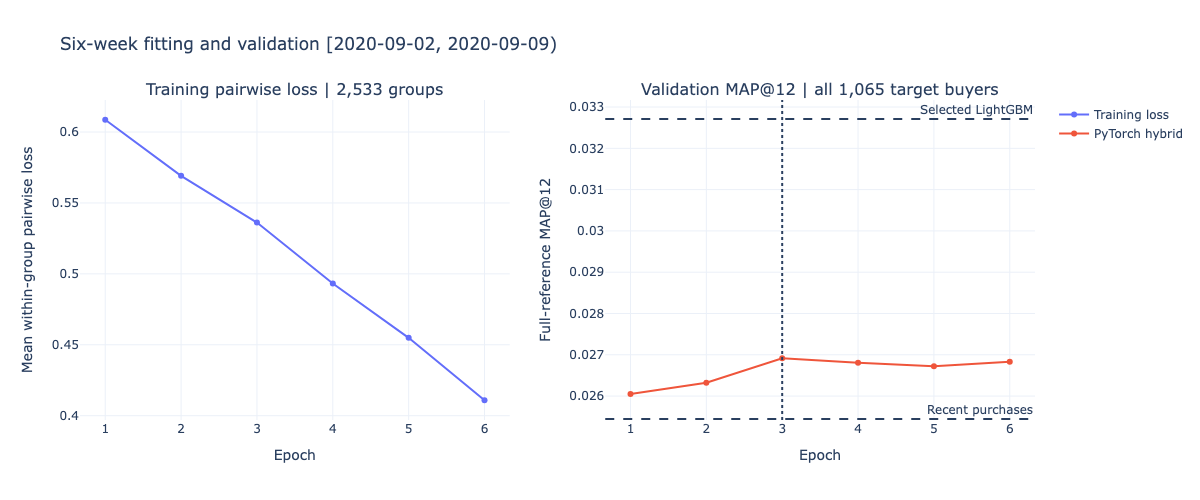

In [16]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

baseline_results = pd.read_csv(
    training_root / "validation/baselines.csv"
)
lightgbm_results = pd.read_csv(
    training_root / "ranker_search/results.csv"
)
selected_lightgbm = lightgbm_results.loc[
    lightgbm_results["method"].eq("lightgbm_leaves_63_min_20")
]

comparison_columns = [
    "method", "evaluated_customers", "target_pairs",
    "map_at_k", "recall_at_k", "ndcg_at_k",
]
comparison = pd.concat([
    baseline_results[comparison_columns],
    selected_lightgbm[comparison_columns],
    pd.DataFrame([{
        "method": "pytorch_hybrid",
        **best_summary,
    }])[comparison_columns],
], ignore_index=True)

comparison.to_csv(run_directory / "comparison.csv", index=False)
display(comparison)

fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=(
        "Training pairwise loss | 2,533 groups",
        "Validation MAP@12 | all 1,065 target buyers",
    ),
)
fig.add_trace(
    go.Scatter(
        x=learning_curve["epoch"],
        y=learning_curve["training_loss"],
        mode="lines+markers",
        name="Training loss",
    ),
    row=1, col=1,
)
fig.add_trace(
    go.Scatter(
        x=learning_curve["epoch"],
        y=learning_curve["validation_map_at_12"],
        mode="lines+markers",
        name="PyTorch hybrid",
    ),
    row=1, col=2,
)

for method, label in [
    ("recent_purchases_180d", "Recent purchases"),
    ("lightgbm_leaves_63_min_20", "Selected LightGBM"),
]:
    value = comparison.loc[
        comparison["method"].eq(method), "map_at_k"
    ].item()
    fig.add_hline(
        y=value, line_dash="dash",
        annotation_text=label, row=1, col=2,
    )

fig.add_vline(
    x=best_epoch, line_dash="dot", row=1, col=2
)
fig.update_xaxes(title_text="Epoch", dtick=1)
fig.update_yaxes(title_text="Mean within-group pairwise loss", row=1, col=1)
fig.update_yaxes(title_text="Full-reference MAP@12", row=1, col=2)
fig.update_layout(
    template="plotly_white",
    title="Six-week fitting and validation [2020-09-02, 2020-09-09)",
    width=1200, height=500,
)

fig.write_html(str(run_directory / "learning_curve.html"))
fig.write_image(str(run_directory / "learning_curve.png"))
fig.show(
    renderer="plotly_mimetype+png",
    config={"displaylogo": False},
)

## Verify the saved model and preprocessing

Reload the selected checkpoint, preprocessing and identifier vocabularies.
Check numeric preprocessing and scores on 1,000 fitting rows.

Then reproduce all saved validation recommendations and metrics.
This verifies persistence without retraining or opening confirmation.

In [17]:
saved_setup = json.loads(
    (run_directory / "setup.json").read_text()
)
saved_selection = json.loads(
    (run_directory / "selection.json").read_text()
)
checkpoint = torch.load(
    run_directory / "best_model.pt",
    map_location="cpu",
    weights_only=True,
)

# JSON represents tuples as lists; compare normalized configurations.
assert (
    json.loads(json.dumps(checkpoint["model_config"]))
    == saved_setup["model_config"]
)
assert checkpoint["epoch"] == saved_selection["best_epoch"]
assert saved_setup["numeric_feature_names"] == numeric_feature_names
assert saved_setup["customer_to_index"] == customer_to_index
assert saved_setup["article_to_index"] == article_to_index

restored_preprocessor = joblib.load(
    run_directory / "numeric_preprocessor.joblib"
)
restored_model = NeuralRanker(**saved_setup["model_config"]).cpu()
restored_model.load_state_dict(checkpoint["model_state_dict"])
restored_model.eval()

probe_rows = 1_000
raw_probe = train_inputs["X"].iloc[:probe_rows].astype("float64")

restored_numeric = np.ascontiguousarray(np.concatenate([
    restored_preprocessor.transform(raw_probe).astype("float32"),
    raw_probe[missing_columns].isna().to_numpy(dtype="float32"),
], axis=1))

np.testing.assert_array_equal(
    restored_numeric, numeric_train[:probe_rows]
)

model.eval()
with torch.inference_mode():
    original_scores = model(
        numeric=train_tensors["numeric"][:probe_rows],
        customer=train_tensors["customer"][:probe_rows],
        article=train_tensors["article"][:probe_rows],
    )
    restored_scores = restored_model(
        numeric=torch.from_numpy(restored_numeric),
        customer=torch.from_numpy(encode_ids(
            train_keys["customer_id"].iloc[:probe_rows],
            saved_setup["customer_to_index"],
        )),
        article=torch.from_numpy(encode_ids(
            train_keys["article_id"].iloc[:probe_rows],
            saved_setup["article_to_index"],
        )),
    )

torch.testing.assert_close(
    original_scores, restored_scores, rtol=0, atol=1e-7
)

restored_evaluation, restored_lists = validate_ranker(restored_model)

assert restored_lists == json.loads(
    (run_directory / "recommendations.json").read_text()
)
assert (
    restored_evaluation["summary"]
    == saved_selection["validation_summary"]
)

verified_files = [
    "best_model.pt", "numeric_preprocessor.joblib",
    "setup.json", "selection.json", "learning_curve.csv",
    "recommendations.json", "customer_scores.csv", "comparison.csv",
]

verification = {
    "selected_epoch": checkpoint["epoch"],
    "probe_rows": probe_rows,
    "reload_max_abs_score_error": (
        original_scores - restored_scores
    ).abs().max().item(),
    "validation_recommendations_identical": True,
    "validation_summary_identical": True,
    "confirmation_evaluated": False,
    "files_sha256": {
        name: file_sha256(run_directory / name)
        for name in verified_files
    },
}

(run_directory / "verification.json").write_text(
    json.dumps(verification, indent=2)
)
display(pd.Series({
    key: value for key, value in verification.items()
    if key != "files_sha256"
}))

selected_epoch                              3
probe_rows                               1000
reload_max_abs_score_error                0.0
validation_recommendations_identical     True
validation_summary_identical             True
confirmation_evaluated                  False
dtype: object

## Record the verified validation experiment in MLflow

Log the existing training history, selected metrics and saved artifacts.
Do not retrain.

Keep a local receipt to reuse a completed logging operation or resume
an interrupted one for the same verified artifacts.

In [18]:
import os
import platform
import sklearn
import mlflow

os.environ.setdefault("MLFLOW_ALLOW_FILE_STORE", "true")
mlflow.set_tracking_uri((PROJECT_ROOT / "mlruns").as_uri())
mlflow.set_experiment("atelier-ai-weekly-v1")

receipt_path = run_directory / "mlflow.json"
verification_sha256 = file_sha256(
    run_directory / "verification.json"
)
receipt = (
    json.loads(receipt_path.read_text())
    if receipt_path.exists() else None
)

if receipt is not None:
    assert receipt["verification_sha256"] == verification_sha256

if receipt is None or receipt["status"] != "complete":
    with mlflow.start_run(
        run_id=receipt["run_id"] if receipt else None,
        run_name="pytorch_hybrid_validation",
    ) as tracked_run:
        receipt = {
            "run_id": tracked_run.info.run_id,
            "verification_sha256": verification_sha256,
            "status": "logging",
        }
        receipt_path.write_text(json.dumps(receipt, indent=2))

        mlflow.log_params({
            **saved_setup["training_config"],
            "embedding_dim": saved_setup["model_config"]["embedding_dim"],
            "hidden_layers": "128,64",
            "dropout": saved_setup["model_config"]["dropout"],
            "numeric_input_count": len(numeric_feature_names),
            "selected_epoch": saved_selection["best_epoch"],
            "python_version": platform.python_version(),
            "torch_version": str(torch.__version__),
            "sklearn_version": sklearn.__version__,
            "numpy_version": np.__version__,
            "pandas_version": pd.__version__,
        })
        mlflow.set_tags({
            "evaluation_role": "validation",
            "system": "pytorch_with_recent_purchases_fallback",
            "confirmation_evaluated": "false",
            "training_rows_sha256": saved_setup["training_rows_sha256"],
            "validation_fingerprint": saved_setup["validation_fingerprint"],
        })

        saved_curve = pd.read_csv(run_directory / "learning_curve.csv")
        for row in saved_curve.to_dict("records"):
            mlflow.log_metrics(
                {
                    key: float(value)
                    for key, value in row.items()
                    if key != "epoch"
                },
                step=int(row["epoch"]),
                synchronous=True,
            )

        mlflow.log_metrics({
            f"selected_{key}": float(value)
            for key, value in saved_selection["validation_summary"].items()
        }, synchronous=True)
        mlflow.log_metric(
            "reload_max_abs_score_error",
            verification["reload_max_abs_score_error"],
        )

        for name in verified_files + [
            "verification.json",
            "learning_curve.html",
            "learning_curve.png",
        ]:
            mlflow.log_artifact(
                str(run_directory / name),
                artifact_path="validation",
            )

    receipt["status"] = "complete"
    receipt_path.write_text(json.dumps(receipt, indent=2))

print("MLflow run:", receipt["run_id"])
print("Logging status:", receipt["status"])

MLflow run: 80721248beeb4cccb96d6e5a068bd9a5
Logging status: complete


## Refit the frozen neural configuration

Reuse the seven-week dataset already prepared for final LightGBM fitting:
892,200 candidate rows, 2,974 informative groups and 4,461 positives.

Refit numeric preprocessing and identifier vocabularies on these rows.
Initialize a new model and train for exactly three epochs.

No early stopping, V1 targets or confirmation outcomes enter this fit.
Preserve the completed six-week validation experiment.

In [19]:
refit_source = (
    PROJECT_ROOT / "data/processed/pipeline_runs/local_v1/training"
)
refit_data_manifest = json.loads(
    (refit_source / "manifest.json").read_text()
)
refit_dataset = refit_source / "dataset"

assert refit_data_manifest["status"] == "complete"
assert refit_data_manifest["uses_v1_targets"] is False
assert refit_data_manifest["feature_columns"] == FEATURE_COLUMNS
assert (
    refit_data_manifest["cohort_sha256"]
    == validation_index["cohort_sha256"]
)

fitting_boundary = pd.Timestamp(
    refit_data_manifest["fitting_boundary_exclusive"]
)
assert fitting_boundary == protocol["v1_evaluation_start"]

for name in ["rows.parquet", "groups.parquet"]:
    assert file_sha256(refit_dataset / name) == (
        refit_data_manifest["artifacts"][name]["sha256"]
    )

with duckdb.connect(
    config={"threads": 2, "memory_limit": "1GB"}
) as connection:
    refit_rows = connection.execute(
        "SELECT * FROM read_parquet(?)",
        [str(refit_dataset / "rows.parquet")],
    ).df()
    saved_refit_groups = connection.execute(
        "SELECT * FROM read_parquet(?)",
        [str(refit_dataset / "groups.parquet")],
    ).df()

assert set(refit_rows["cutoff"].unique()) == set(
    pd.to_datetime(refit_data_manifest["training_cutoffs"])
)
assert (
    refit_rows["cutoff"]
    + pd.Timedelta(days=protocol["horizon_days"])
).le(fitting_boundary).all()

# For final fitting, this helper checks the enlarged fitting boundary.
refit_inputs = prepare_ranker_inputs(
    refit_rows,
    validation_cutoff=fitting_boundary,
)
pd.testing.assert_frame_equal(
    refit_inputs["group_index"], saved_refit_groups
)

assert len(refit_inputs["X"]) == 892_200
assert len(refit_inputs["groups"]) == 2_974
assert int(refit_inputs["y"].sum()) == 4_461
del refit_rows

display(pd.Series({
    "training_rows": len(refit_inputs["X"]),
    "informative_groups": len(refit_inputs["groups"]),
    "positive_rows": int(refit_inputs["y"].sum()),
    "last_target_end_exclusive": fitting_boundary,
}))

training_rows                             892200
informative_groups                          2974
positive_rows                               4461
last_target_end_exclusive    2020-09-09 00:00:00
dtype: object

In [20]:
from sklearn.base import clone

# Preserve preprocessing choices, discard the six-week fitted statistics.
refit_preprocessor = clone(restored_preprocessor)
refit_raw_numeric = refit_inputs["X"].astype("float64")

refit_numeric = np.ascontiguousarray(np.concatenate([
    refit_preprocessor.fit_transform(
        refit_raw_numeric
    ).astype("float32"),
    refit_raw_numeric[missing_columns]
    .isna()
    .to_numpy(dtype="float32"),
], axis=1))

assert refit_numeric.shape == (892_200, 37)
assert np.isfinite(refit_numeric).all()

refit_keys = refit_inputs["keys"]
refit_customer_to_index = {
    identifier: index
    for index, identifier in enumerate(
        sorted(refit_keys["customer_id"].unique()), start=1
    )
}
refit_article_to_index = {
    identifier: index
    for index, identifier in enumerate(
        sorted(refit_keys["article_id"].unique()), start=1
    )
}

refit_tensors = {
    "numeric": torch.from_numpy(refit_numeric),
    "customer": torch.from_numpy(encode_ids(
        refit_keys["customer_id"], refit_customer_to_index
    )),
    "article": torch.from_numpy(encode_ids(
        refit_keys["article_id"], refit_article_to_index
    )),
    "label": torch.from_numpy(
        refit_inputs["y"].to_numpy(dtype="int64", copy=True)
    ),
}

refit_group_rows = (
    torch.from_numpy(
        refit_inputs["group_index"]["row_start"]
        .to_numpy(dtype="int64", copy=True)
    )[:, None]
    + torch.arange(CANDIDATES_PER_GROUP)[None, :]
)
assert torch.equal(
    refit_group_rows.reshape(-1),
    torch.arange(len(refit_inputs["X"])),
)

refit_model_config = {
    **saved_setup["model_config"],
    "n_customers": len(refit_customer_to_index) + 1,
    "n_articles": len(refit_article_to_index) + 1,
}
refit_epochs = int(saved_selection["best_epoch"])
assert refit_epochs == 3

In [21]:
refit_directory = run_directory / "final_refit"
refit_directory.mkdir(parents=True, exist_ok=False)

refit_protocol = {
    "role": "fixed_budget_final_refit",
    "source_validation_run": str(run_directory.relative_to(PROJECT_ROOT)),
    "source_selection_sha256": file_sha256(
        run_directory / "selection.json"
    ),
    "source_verification_sha256": file_sha256(
        run_directory / "verification.json"
    ),
    "training_manifest_sha256": file_sha256(
        refit_source / "manifest.json"
    ),
    "training_rows_sha256": (
        refit_data_manifest["artifacts"]["rows.parquet"]["sha256"]
    ),
    "training_cutoffs": refit_data_manifest["training_cutoffs"],
    "model_config": refit_model_config,
    "training_config": {
        **saved_setup["training_config"],
        "epochs": refit_epochs,
        "early_stopping": False,
    },
    "numeric_feature_names": numeric_feature_names,
    "loss_aggregation": "mean within groups, then mean across groups",
    "negative_sampling": "none",
    "uses_v1_targets": False,
    "confirmation_evaluated": False,
}
(refit_directory / "protocol.json").write_text(
    json.dumps(refit_protocol, indent=2)
)

torch.manual_seed(saved_setup["training_config"]["seed"])
refit_model = NeuralRanker(**refit_model_config).cpu()
refit_optimizer = torch.optim.AdamW(
    refit_model.parameters(),
    lr=saved_setup["training_config"]["learning_rate"],
    weight_decay=saved_setup["training_config"]["weight_decay"],
)
refit_loader = DataLoader(
    TensorDataset(refit_group_rows),
    batch_size=saved_setup["training_config"]["group_batch_size"],
    shuffle=True,
    generator=torch.Generator().manual_seed(
        saved_setup["training_config"]["seed"]
    ),
    num_workers=0,
    drop_last=False,
)

refit_history = []

for epoch in range(1, refit_epochs + 1):
    started = perf_counter()
    refit_model.train()
    loss_sum = 0.0
    groups_seen = 0

    for (row_indices,) in refit_loader:
        batch = {
            name: tensor[row_indices]
            for name, tensor in refit_tensors.items()
        }
        refit_optimizer.zero_grad(set_to_none=True)
        scores = refit_model(
            batch["numeric"], batch["customer"], batch["article"]
        )
        loss = pairwise_ranking_loss(scores, batch["label"])
        loss.backward()
        refit_optimizer.step()

        loss_sum += loss.detach().item() * len(row_indices)
        groups_seen += len(row_indices)

    assert groups_seen == 2_974
    refit_history.append({
        "epoch": epoch,
        "training_loss": loss_sum / groups_seen,
        "fit_seconds": perf_counter() - started,
    })
    print(
        f"Refit epoch {epoch}/{refit_epochs} | "
        f"loss={refit_history[-1]['training_loss']:.5f} | "
        f"fit={refit_history[-1]['fit_seconds']:.2f}s",
        flush=True,
    )

refit_model.eval()

torch.save({
    "model_state_dict": refit_model.state_dict(),
    "model_config": refit_model_config,
    "epochs": refit_epochs,
}, refit_directory / "model.pt")

joblib.dump(
    refit_preprocessor,
    refit_directory / "numeric_preprocessor.joblib",
)
(refit_directory / "vocabularies.json").write_text(
    json.dumps({
        "customer_to_index": refit_customer_to_index,
        "article_to_index": refit_article_to_index,
    })
)

refit_curve = pd.DataFrame(refit_history)
refit_curve.to_csv(
    refit_directory / "learning_curve.csv", index=False
)

Refit epoch 1/3 | loss=0.60458 | fit=1.46s
Refit epoch 2/3 | loss=0.55834 | fit=1.45s
Refit epoch 3/3 | loss=0.52260 | fit=1.43s


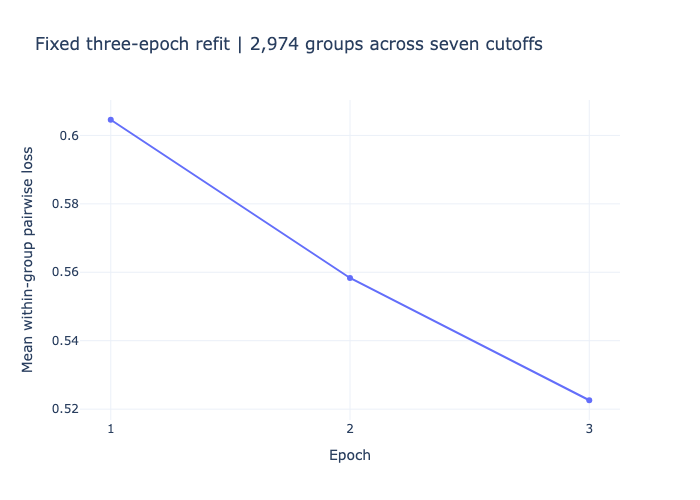

status                        complete
training_rows                   892200
training_groups                   2974
positive_training_rows            4461
epochs                               3
fitted_customers                  2406
fitted_articles                  14454
reload_probe_rows                 1000
reload_max_abs_score_error         0.0
uses_v1_targets                  False
confirmation_evaluated           False
dtype: object

In [22]:
refit_checkpoint = torch.load(
    refit_directory / "model.pt",
    map_location="cpu",
    weights_only=True,
)
reloaded_refit_model = NeuralRanker(
    **refit_checkpoint["model_config"]
).cpu()
reloaded_refit_model.load_state_dict(
    refit_checkpoint["model_state_dict"]
)
reloaded_refit_model.eval()

probe_positions = np.linspace(
    0, len(refit_inputs["X"]) - 1, num=1_000, dtype="int64"
)
probe_batch = {
    name: tensor[probe_positions]
    for name, tensor in refit_tensors.items()
    if name != "label"
}

with torch.inference_mode():
    refit_before = refit_model(**probe_batch)
    refit_after = reloaded_refit_model(**probe_batch)

torch.testing.assert_close(
    refit_before, refit_after, rtol=0, atol=1e-7
)

refit_report = {
    "status": "complete",
    "training_rows": len(refit_inputs["X"]),
    "training_groups": len(refit_inputs["groups"]),
    "positive_training_rows": int(refit_inputs["y"].sum()),
    "epochs": refit_epochs,
    "fitted_customers": len(refit_customer_to_index),
    "fitted_articles": len(refit_article_to_index),
    "reload_probe_rows": len(probe_positions),
    "reload_max_abs_score_error": (
        refit_before - refit_after
    ).abs().max().item(),
    "uses_v1_targets": False,
    "confirmation_evaluated": False,
    "files_sha256": {
        name: file_sha256(refit_directory / name)
        for name in [
            "model.pt", "numeric_preprocessor.joblib",
            "vocabularies.json", "protocol.json", "learning_curve.csv",
        ]
    },
}
(refit_directory / "manifest.json").write_text(
    json.dumps(refit_report, indent=2)
)

import plotly.express as px

fig = px.line(
    refit_curve,
    x="epoch",
    y="training_loss",
    markers=True,
    labels={
        "epoch": "Epoch",
        "training_loss": "Mean within-group pairwise loss",
    },
    title="Fixed three-epoch refit | 2,974 groups across seven cutoffs",
    template="plotly_white",
)
fig.update_xaxes(dtick=1)
fig.write_html(str(refit_directory / "learning_curve.html"))
fig.write_image(str(refit_directory / "learning_curve.png"))
fig.show(
    renderer="plotly_mimetype+png",
    config={"displaylogo": False},
)

display(pd.Series({
    key: value for key, value in refit_report.items()
    if key != "files_sha256"
}))

## Track the final refit

Record the fixed three-epoch refit separately from model selection.
Log fitting history, persistence checks and final artifacts.

No validation-based selection or new training occurs in this step.

In [23]:
refit_report = json.loads(
    (refit_directory / "manifest.json").read_text()
)
refit_spec = json.loads(
    (refit_directory / "protocol.json").read_text()
)

for name, digest in refit_report["files_sha256"].items():
    assert file_sha256(refit_directory / name) == digest

refit_manifest_sha256 = file_sha256(
    refit_directory / "manifest.json"
)
refit_receipt_path = refit_directory / "mlflow.json"
refit_receipt = (
    json.loads(refit_receipt_path.read_text())
    if refit_receipt_path.exists() else None
)

if refit_receipt:
    assert (
        refit_receipt["manifest_sha256"]
        == refit_manifest_sha256
    )

mlflow.set_tracking_uri((PROJECT_ROOT / "mlruns").as_uri())
mlflow.set_experiment("atelier-ai-weekly-v1")

if refit_receipt is None or refit_receipt["status"] != "complete":
    with mlflow.start_run(
        run_id=refit_receipt["run_id"] if refit_receipt else None,
        run_name="pytorch_hybrid_final_refit",
    ) as tracked_run:
        refit_receipt = {
            "run_id": tracked_run.info.run_id,
            "manifest_sha256": refit_manifest_sha256,
            "status": "logging",
        }
        refit_receipt_path.write_text(
            json.dumps(refit_receipt, indent=2)
        )

        mlflow.log_params({
            "epochs": refit_report["epochs"],
            "early_stopping": False,
            "learning_rate": refit_spec["training_config"]["learning_rate"],
            "weight_decay": refit_spec["training_config"]["weight_decay"],
            "seed": refit_spec["training_config"]["seed"],
            "group_batch_size": refit_spec["training_config"]["group_batch_size"],
            "embedding_dim": refit_spec["model_config"]["embedding_dim"],
            "hidden_layers": "128,64",
            "dropout": refit_spec["model_config"]["dropout"],
            "torch_version": str(torch.__version__),
            "sklearn_version": sklearn.__version__,
        })
        mlflow.set_tags({
            "role": "final_train_plus_validation_refit",
            "uses_v1_targets": "false",
            "confirmation_evaluated": "false",
            "source_validation_mlflow_run": receipt["run_id"],
        })

        for row in pd.read_csv(
            refit_directory / "learning_curve.csv"
        ).to_dict("records"):
            mlflow.log_metrics({
                "training_loss": float(row["training_loss"]),
                "fit_seconds": float(row["fit_seconds"]),
            }, step=int(row["epoch"]), synchronous=True)

        mlflow.log_metrics({
            key: float(refit_report[key])
            for key in [
                "training_rows", "training_groups",
                "positive_training_rows", "fitted_customers",
                "fitted_articles", "reload_max_abs_score_error",
            ]
        }, synchronous=True)

        for name in [
            *refit_report["files_sha256"],
            "manifest.json", "learning_curve.html", "learning_curve.png",
        ]:
            mlflow.log_artifact(
                str(refit_directory / name),
                artifact_path="final_refit",
            )

    refit_receipt["status"] = "complete"
    refit_receipt_path.write_text(
        json.dumps(refit_receipt, indent=2)
    )

print("Final-refit MLflow run:", refit_receipt["run_id"])
print("Logging status:", refit_receipt["status"])

Final-refit MLflow run: 5119e84431e64da3ac6b8f4c2ec6eebd
Logging status: complete


## Freeze the final comparison protocol

Freeze model artifacts, retrieval, temporal boundaries, metric
conventions and paired bootstrap before computing confirmation outcomes.

Historical inputs may include purchases strictly before 2020-09-16.
Both fitted models retain their existing seven-week fitting boundary.

LightGBM remains the validation-selected system.
Confirmation will assess the frozen comparison without retuning.

In [24]:
import ast
from hashlib import sha256

lightgbm_directory = (
    PROJECT_ROOT / "data/processed/pipeline_runs/local_v1/model"
)
lightgbm_manifest = json.loads(
    (lightgbm_directory / "manifest.json").read_text()
)
lightgbm_model_path = lightgbm_directory / "bundle/model.txt"

assert file_sha256(lightgbm_model_path) == (
    lightgbm_manifest["artifacts"]["model.txt"]["sha256"]
)
assert lightgbm_manifest["num_trees"] == 8
assert refit_receipt["status"] == "complete"

# Hash the shared class definition independently of notebook outputs.
import atelier_ai.neural_ranker as neural_ranker_module

model_source = Path(neural_ranker_module.__file__).read_text()
model_definitions = [
    ast.get_source_segment(model_source, node)
    for node in ast.parse(model_source).body
    if isinstance(node, ast.ClassDef) and node.name == "NeuralRanker"
]
assert len(model_definitions) == 1

original_decision = json.loads(
    (training_root / "final_selection.json").read_text()
)["decision"]

comparison_protocol = {
    "schema_version": 1,
    "status": "frozen_before_confirmation",
    "start_inclusive": str(protocol["confirmation_start"].date()),
    "end_exclusive": str(protocol["confirmation_end_exclusive"].date()),
    "fitting_boundary_exclusive": str(fitting_boundary.date()),
    "history_days": protocol["history_days"],
    "recipients": 20_000,
    "cohort_sha256": validation_index["cohort_sha256"],
    "cohort_file": str(
        (refit_dataset / "cohort.csv").relative_to(PROJECT_ROOT)
    ),
    "cohort_file_sha256": file_sha256(refit_dataset / "cohort.csv"),
    "recommendations_per_recipient": 12,
    "retrieval": original_decision["retrieval"],
    "feature_columns": FEATURE_COLUMNS,
    "numeric_feature_names": numeric_feature_names,
    "methods": [
        "recent_popularity_7d",
        "preferred_product_types",
        "recent_purchases_180d",
        "lightgbm_leaves_63_min_20",
        "pytorch_hybrid",
    ],
    "selection_metric": "full_reference_map_at_12",
    "secondary_metrics": ["recall_at_12", "ndcg_at_12"],
    "target_population": "all target buyers, including zero-hit buyers",
    "full_reference_targets": True,
    "tie_break": "score descending, article_id ascending",
    "validation_selected_method": "lightgbm_leaves_63_min_20",
    "retune_after_confirmation": False,
    "pytorch_refit_directory": str(
        refit_directory.relative_to(PROJECT_ROOT)
    ),
    "pytorch_manifest_sha256": refit_manifest_sha256,
    "pytorch_files_sha256": refit_report["files_sha256"],
    "pytorch_mlflow_run_id": refit_receipt["run_id"],
    "pytorch_unknown_customer_policy": "recent_purchases_180d",
    "pytorch_unknown_article_policy": "zero_embedding_with_numeric_features",
    "pytorch_class_sha256": sha256(
        model_definitions[0].encode()
    ).hexdigest(),
    "lightgbm_model_file": str(
        lightgbm_model_path.relative_to(PROJECT_ROOT)
    ),
    "lightgbm_model_sha256": file_sha256(lightgbm_model_path),
    "bootstrap": {
        "model_method": "pytorch_hybrid",
        "baseline_method": "lightgbm_leaves_63_min_20",
        "unit": "target buyer",
        "paired": True,
        "resamples": 5_000,
        "seed": 42,
        "batch_size": 250,
        "confidence_level": 0.95,
        "interval_method": "percentile",
    },
    "source_sha256": {
        str(path.relative_to(PROJECT_ROOT)): file_sha256(path)
        for path in sorted(
            (PROJECT_ROOT / "src/atelier_ai").glob("*.py")
        )
    },
    "confirmation_evaluated_at_freeze": False,
}

confirmation_directory = run_directory / "confirmation"
confirmation_directory.mkdir(exist_ok=True)
comparison_protocol_path = confirmation_directory / "protocol.json"

if comparison_protocol_path.exists():
    assert (
        json.loads(comparison_protocol_path.read_text())
        == comparison_protocol
    ), "The frozen comparison protocol differs."
else:
    with comparison_protocol_path.open("x") as stream:
        json.dump(comparison_protocol, stream, indent=2)

print("Comparison protocol frozen:", comparison_protocol_path)
print("Confirmation outcomes remain uncomputed.")

Comparison protocol frozen: /Users/oumar/Developer/portfolio/atelier-ai-project/data/processed/pytorch_v1/44eb810a8212/confirmation/protocol.json
Confirmation outcomes remain uncomputed.


## Next step

The validation experiment and fixed-budget final refit are preserved above.
Use `09_final_confirmation.ipynb` in a fresh kernel to evaluate the saved
confirmation predictions. Its configured campaign is explicit; rerunning this
training notebook does not silently change the campaign used for confirmation.
